# Training a SOM model on CESM data

## Data prep:

In [1]:
print("Load data and imports")

Load data and imports


In [2]:
# Data handling
import xarray as xr
import numpy as np
import pandas as pd
# Plotting
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.path as mpath # Used for circular matplotlib figures
import cartopy.feature as cfeature
import cartopy.util as cutil
# Regridding
import xesmf as xe
# SOM training
from minisom import MiniSom
import pickle
from itertools import product
import sammon
import time

In [3]:
### Load data with xarray ###
file_path = "./PSL_data/"
files_early = [
    "b.e21.BSSP370cmip6.f09_g17.LE2-1001.001.cam.h1.PSL.DJF_2015-2024.1.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1021.002.cam.h1.PSL.DJF_2015-2024.2.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1041.003.cam.h1.PSL.DJF_2015-2024.3.nc",  
    "b.e21.BSSP370cmip6.f09_g17.LE2-1061.004.cam.h1.PSL.DJF_2015-2024.4.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1081.005.cam.h1.PSL.DJF_2015-2024.5.nc",  
    "b.e21.BSSP370cmip6.f09_g17.LE2-1101.006.cam.h1.PSL.DJF_2015-2024.6.nc",  
    "b.e21.BSSP370cmip6.f09_g17.LE2-1121.007.cam.h1.PSL.DJF_2015-2024.7.nc",  
    "b.e21.BSSP370cmip6.f09_g17.LE2-1141.008.cam.h1.PSL.DJF_2015-2024.8.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1161.009.cam.h1.PSL.DJF_2015-2024.9.nc",  
    "b.e21.BSSP370cmip6.f09_g17.LE2-1181.010.cam.h1.PSL.DJF_2015-2024.10.nc", 
]
files_early = [file_path + file for file in files_early]

files_late = [
    "b.e21.BSSP370cmip6.f09_g17.LE2-1001.001.cam.h1.PSL.DJF_2085-2094.1.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1021.002.cam.h1.PSL.DJF_2085-2094.2.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1041.003.cam.h1.PSL.DJF_2085-2094.3.nc",
    "b.e21.BSSP370cmip6.f09_g17.LE2-1061.004.cam.h1.PSL.DJF_2085-2094.4.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1081.005.cam.h1.PSL.DJF_2085-2094.5.nc",
    "b.e21.BSSP370cmip6.f09_g17.LE2-1101.006.cam.h1.PSL.DJF_2085-2094.6.nc",
    "b.e21.BSSP370cmip6.f09_g17.LE2-1121.007.cam.h1.PSL.DJF_2085-2094.7.nc",
    "b.e21.BSSP370cmip6.f09_g17.LE2-1141.008.cam.h1.PSL.DJF_2085-2094.8.nc", 
    "b.e21.BSSP370cmip6.f09_g17.LE2-1161.009.cam.h1.PSL.DJF_2085-2094.9.nc",
    "b.e21.BSSP370cmip6.f09_g17.LE2-1181.010.cam.h1.PSL.DJF_2085-2094.10.nc"
]

files_late = [file_path + file for file in files_late]

ds_early = xr.open_mfdataset(
    files_early, 
    combine='nested',
    concat_dim='ensemble'
)
ds_late = xr.open_mfdataset(
    files_late, 
    combine='nested',
    concat_dim='ensemble'
)


# ds_early = xr.open_dataset(filepath + "/b.e21.BSSP370cmip6.f09_g17.LE2-1001.001.cam.h1.PSL.DJF_2015-2024.1.nc") # Code for single ensemble member
# ds_late = xr.open_dataset(filepath + "/b.e21.BSSP370cmip6.f09_g17.LE2-1001.001.cam.h1.PSL.DJF_2085-2094.1.nc")
ds_full = xr.concat([ds_early, ds_late], dim='time').compute()

## Regridding to EASE grid

In [4]:
ease_grid_full = xr.open_dataset("ease_nh50km_coordinates.nc") # Entire Northern Hemisphere
ease_grid_subset = ease_grid_full.isel(col=[a for a in range(180 - 60, 180 + 40)], row=[a for a in range(180 - 100, 180 + 20)])

In [5]:
time_data = ds_full['time']
ds_subset = ds_full.where(ds_full['time'].dt.month.isin([12, 1, 2]), drop=True)
ds_subset

<xarray.Dataset> Size: 4GB
Dimensions:       (time: 1800, ensemble: 10, lat: 192, lon: 288, ilev: 33,
                   lev: 32, nbnd: 2)
Coordinates:
  * ilev          (ilev) float64 264B 2.255 5.032 10.16 ... 967.5 985.1 1e+03
  * lat           (lat) float64 2kB -90.0 -89.06 -88.12 ... 88.12 89.06 90.0
  * lev           (lev) float64 256B 3.643 7.595 14.36 ... 957.5 976.3 992.6
  * lon           (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 356.2 357.5 358.8
  * time          (time) object 14kB 2015-01-01 00:00:00 ... 2094-12-31 00:00:00
Dimensions without coordinates: ensemble, nbnd
Data variables: (12/26)
    P0            (time, ensemble) float64 144kB 1e+05 1e+05 ... 1e+05 1e+05
    PSL           (ensemble, time, lat, lon) float32 4GB 1.01e+05 ... 9.821e+04
    ch4vmr        (ensemble, time) float64 144kB 1.837e-06 ... 3.283e-06
    co2vmr        (ensemble, time) float64 144kB 0.0003988 ... 0.0008223
    date          (ensemble, time) float64 144kB 2.015e+07 ... 2.094e+07
    date_written  (ensemble, time) object 144kB b'10/22/24' ... b'10/22/24'
    ...            ...
    nsbase        (time, ensemble) float64 144kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    nscur         (ensemble, time) float64 144kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    nsteph        (ensemble, time) float64 144kB 0.0 48.0 ... 1.402e+06
    sol_tsi       (ensemble, time) float64 144kB -1.0 -1.0 -1.0 ... -1.0 -1.0
    time_bnds     (ensemble, time, nbnd) object 288kB 2015-01-01 00:00:00 ......
    time_written  (ensemble, time) object 144kB b'21:48:09' ... b'21:53:22'
Attributes:
    Conventions:       CF-1.0
    source:            CAM
    case:              b.e21.BSSP370cmip6.f09_g17.LE2-1001.001
    logname:           sunseon
    host:              mom2
    initial_file:      b.e21.BHISTcmip6.f09_g17.LE2-1001.001.cam.i.2015-01-01...
    topography_file:   /mnt/lustre/share/CESM/cesm_input/atm/cam/topo/fv_0.9x...
    model_doi_url:     https://doi.org/10.5065/D67H1H0V
    time_period_freq:  day_1
    history:           Tue Oct 22 21:48:09 2024: ncrcat -n 10,4,1 b.e21.BSSP3...
    NCO:               netCDF Operators version 5.1.9 (Homepage = http://nco....

In [6]:
lon_target, lat_target = ease_grid_subset['lon2d'], ease_grid_subset['lat2d']
lon_source, lat_source = ds_full['lon'], ds_full['lat']

source_grid = {'lat': lat_source, 'lon': lon_source}
target_grid = {'lat': lat_target, 'lon': lon_target}

regridder = xe.Regridder(ds_full, target_grid, method='bilinear', periodic=True)
ds_regridded = regridder(ds_full)

In [7]:
ds_regridded

<xarray.Dataset> Size: 864MB
Dimensions:  (ensemble: 10, time: 1800, row: 120, col: 100, ilev: 33, lev: 32)
Coordinates:
  * ilev     (ilev) float64 264B 2.255 5.032 10.16 18.56 ... 967.5 985.1 1e+03
  * lev      (lev) float64 256B 3.643 7.595 14.36 24.61 ... 957.5 976.3 992.6
  * time     (time) object 14kB 2015-01-01 00:00:00 ... 2094-12-31 00:00:00
  * col      (col) float32 400B 120.0 121.0 122.0 123.0 ... 217.0 218.0 219.0
  * row      (row) float32 480B 80.0 81.0 82.0 83.0 ... 196.0 197.0 198.0 199.0
    lat2d    (row, col) float32 48kB 35.55 35.81 36.06 ... 71.01 70.6 70.19
    lon2d    (row, col) float32 48kB -149.1 -149.5 -149.9 ... 62.67 63.29 63.87
Dimensions without coordinates: ensemble
Data variables:
    PSL      (ensemble, time, row, col) float32 864MB 1.01e+05 ... 1.035e+05
Attributes:
    regrid_method:  bilinear

In [8]:
# define the normalizing data function
# def normalize_data(data):
#     """
#     Function for normalizing data prior to training using z-score
#     """
#     return (data - np.nanmean(data)) / np.nanstd(data)
#     # return data

In [9]:
### Transform data to prep for training ###
num_ensembles, num_times, num_lats, num_lons = ds_regridded['PSL'].shape
# Compute anomalies by subtracting the spatial mean
spatial_mean = ds_regridded['PSL'].mean(dim=['ensemble', 'time'])  # shape: (lat, lon)
subset_anomalies = ds_regridded['PSL'] - spatial_mean
subsetarray = subset_anomalies.compute().values.reshape(num_times * num_ensembles, num_lats*num_lons)
# subsetarray = ds_regridded['PSL'].compute().values.reshape(num_times * num_ensembles, num_lats*num_lons)

# Model Creation and Training:

In [10]:
n_neurons = 4
m_neurons = 4
som_grid_rows = [n_neurons]    # (y-axis)
som_grid_cols = [m_neurons]    # (x-axis)

In [11]:
# set other attributes required for som training
input_length = subsetarray.shape[1]      # Total number of points to train on per timestep (observation)
decay_function = 'asymptotic_decay'        # Function that reduces learning_rate and sigma at each iteration
neighborhood_function = 'gaussian'       # Function that weights the neighborhood of a position in the map
topology = 'rectangular'                 # Topology of the map; Possible values: 'rectangular', 'hexagonal'
activation_distance = 'euclidean'        # Distance used to activate the map; Possible values: 'euclidean', 'cosine', 'manhattan', 'chebyshev'
random_seed = 1                          # Random seed to use for reproducibility. Using 1.
random_order = True
verbose = False # True

In [12]:
# Decide permutations we will train

# sigma is decided later: spread of neighborhood function - sigma - is set below and depends on the som shape
###sigma            = [1.0, 0.5, 0.25, 0.1]
# initial learning rate (at the iteration t we have learning_rate(t) = learning_rate / (1 + t/T) where T is #num_iteration/2)
# model_set = 5
learning_rate    = [0.01, 0.05, 0.5]
num_iteration    = [100000, 500000, 1000000]
# sigma = list(np.hstack([0.5,list(range(1,n_neurons,1))]))
sigma = [2, 3]
list_of_sigs = []
list_of_lrts = []
list_of_itrs = []
for sig, lr, n_iter in product(sigma, learning_rate, num_iteration):
    list_of_sigs.append(sig)
    list_of_lrts.append(lr)
    list_of_itrs.append(n_iter)
print(f"Total model runs: {len(list_of_sigs)}")

Total model runs: 18


In [13]:
import os
output_path = f'som{n_neurons}x{m_neurons}_norm2/'
os.makedirs(output_path, exist_ok=True)
os.makedirs(f'{output_path}/models/', exist_ok=True)
os.makedirs(f'{output_path}/sammons/', exist_ok=True)

In [14]:
for num_grid, (som_row, som_col) in enumerate(zip(som_grid_rows, som_grid_cols)):
    print('Testing grid: ' + str(som_row) + 'x' + str(som_col))

    fout = os.path.join(output_path, f'qerror{som_row}x{som_col}.csv')
    # sigma = list(np.hstack([0.5, list(range(1, som_col, 1))]))
    sigma = [2, 3]

    list_of_sigs = []
    list_of_lrts = []
    list_of_itrs = []
    for sig, lr, n_iter in product(sigma, learning_rate, num_iteration):
        list_of_sigs.append(sig)
        list_of_lrts.append(lr)
        list_of_itrs.append(n_iter)

    for num_exp, (sig, lr, n_iter) in enumerate(zip(list_of_sigs, list_of_lrts, list_of_itrs)):
        # if(num_exp not in models):
        #     continue
        start = time.time()
        print(f'Testing {num_exp+1} of {len(list_of_sigs)}')
        if(num_exp not in [16, 17, 18, 19]):
            continue

        # data = normalize_data(subsetarray) # Normalize data
        data = subsetarray / 100             # or convert to hPa

        som = MiniSom(
            som_row, som_col, input_length, sig, lr, decay_function,
            neighborhood_function, topology, activation_distance, random_seed
        )

        som.pca_weights_init(data)
        som.train(data, n_iter, random_order, verbose)

        # Save model
        model_path = os.path.join(output_path, 'models', f'som{num_exp}.pickle')
        with open(model_path, 'wb') as model_file:
            pickle.dump(som, model_file)

        # Save single row to CSV immediately
        row = pd.DataFrame([{
            "n_row": som_row,
            "n_col": som_col,
            "sigma": sig,
            "lr": lr,
            "n_iter": n_iter,
            "q_error": som.quantization_error(data)
        }])
        row.to_csv(fout, mode='a', header=not os.path.exists(fout), index=False)

        print(f"Training complete after {time.time() - start:.2f} seconds")


Testing grid: 4x4
Testing 1 of 18
Testing 2 of 18
Testing 3 of 18
Testing 4 of 18
Testing 5 of 18
Testing 6 of 18
Testing 7 of 18
Testing 8 of 18
Testing 9 of 18
Testing 10 of 18
Testing 11 of 18
Testing 12 of 18
Testing 13 of 18
Testing 14 of 18
Testing 15 of 18
Testing 16 of 18
Testing 17 of 18


/opt/anaconda3/envs/SOM/lib/python3.13/site-packages/minisom.py:447: ComplexWarning: Casting complex values to real discards the imaginary part
  self._weights[i, j] = c1*pc[pc_order[0]] + \


Training complete after 5328.23 seconds
Testing 18 of 18
Training complete after 5845.11 seconds
Finished all experiments for SOM grid 4x4


# Sammon Maps

som4x4_norm2//models/som0.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som1.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som2.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som3.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som4.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som5.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som6.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som7.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som8.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som9.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som10.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som11.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som12.pickle
TolFun exceeded: Optimisation terminated
som4x4_norm2//models/som13.pickle
T

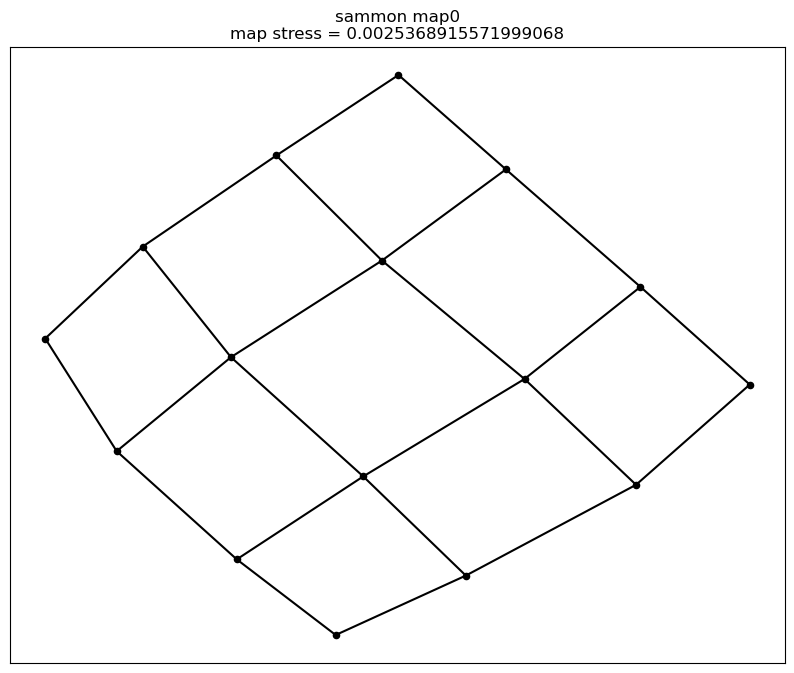

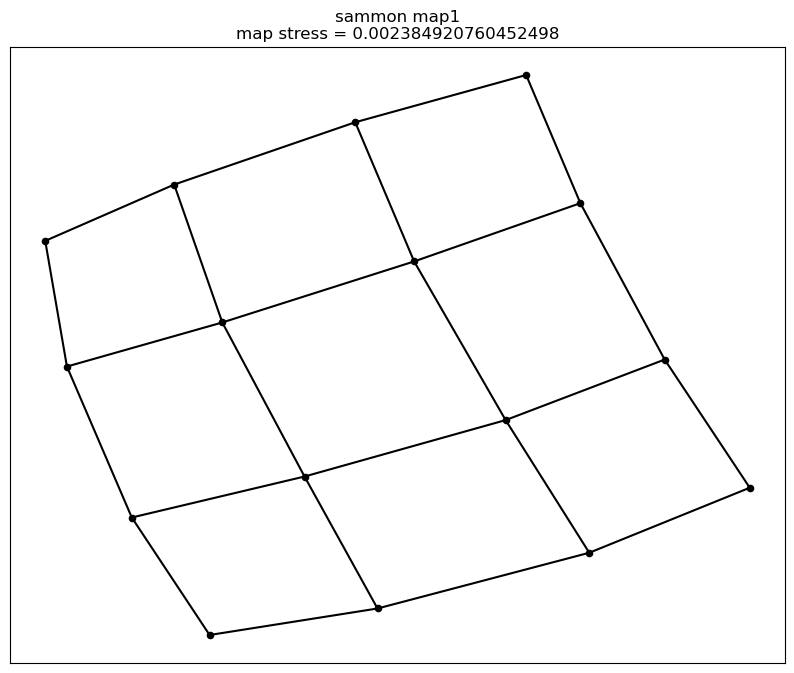

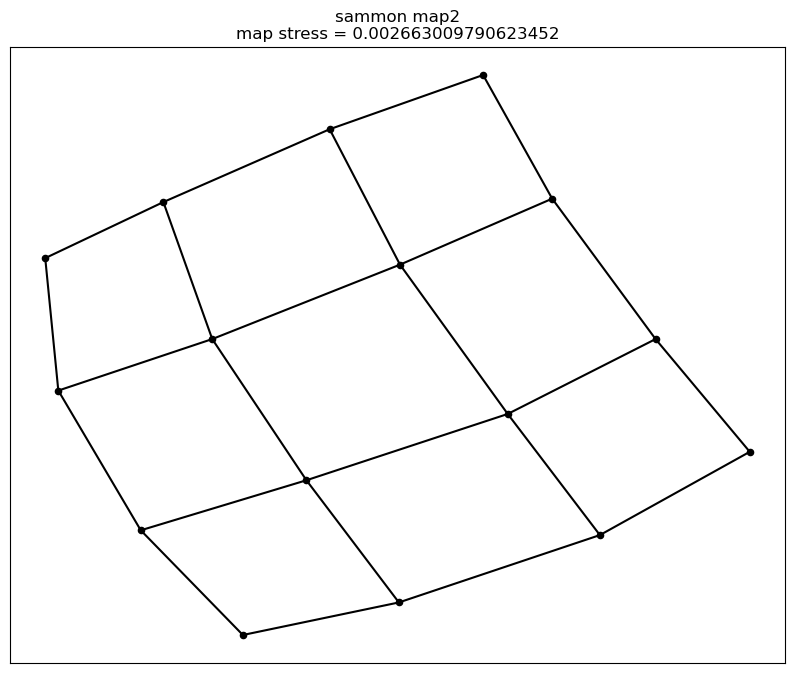

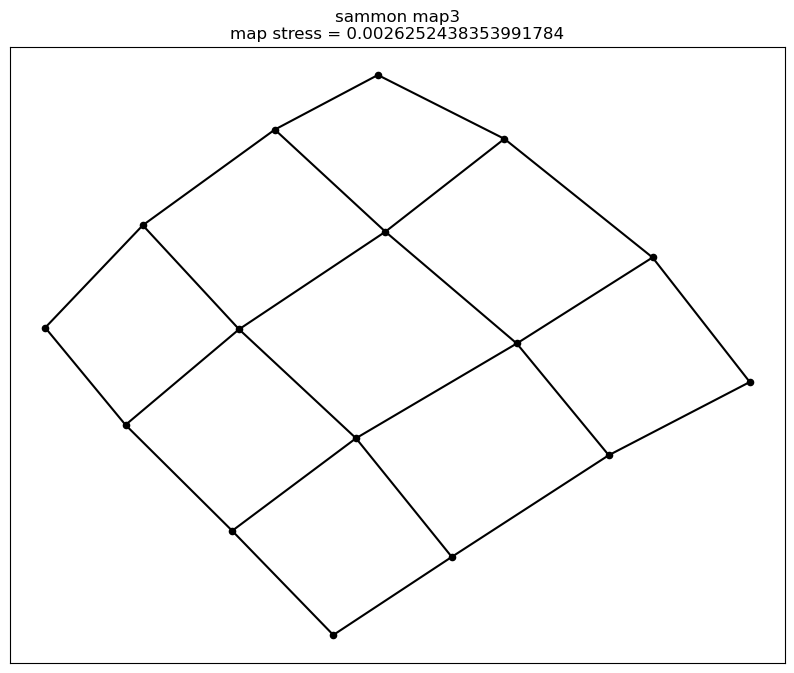

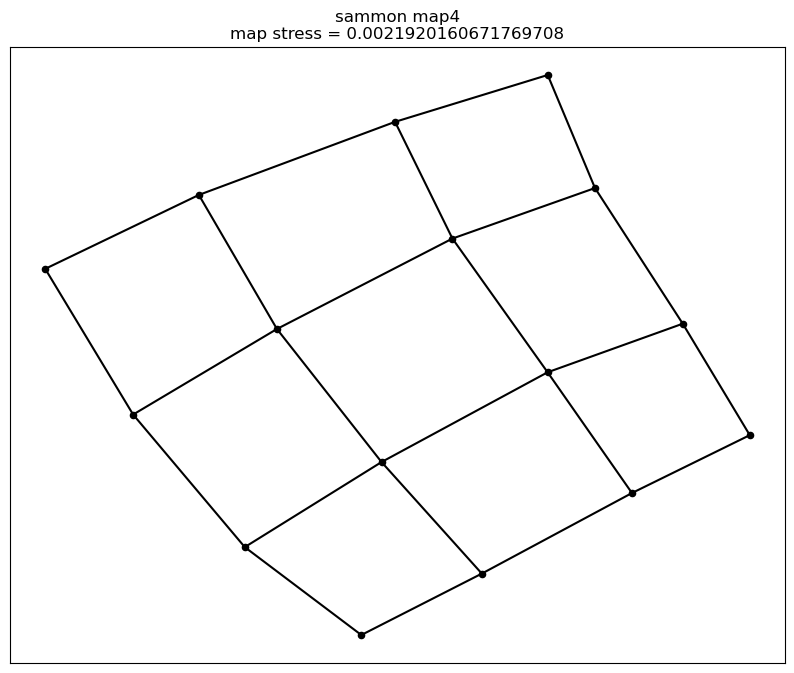

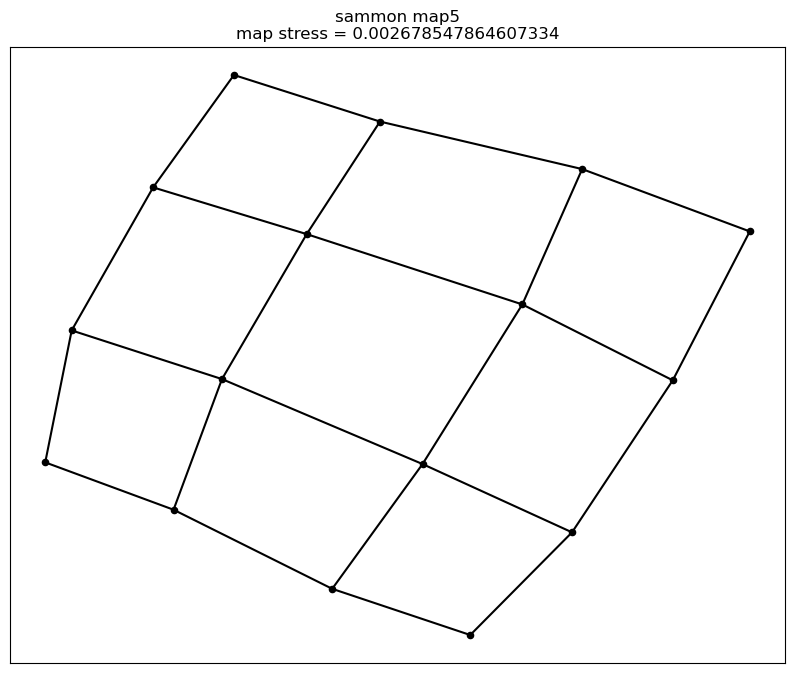

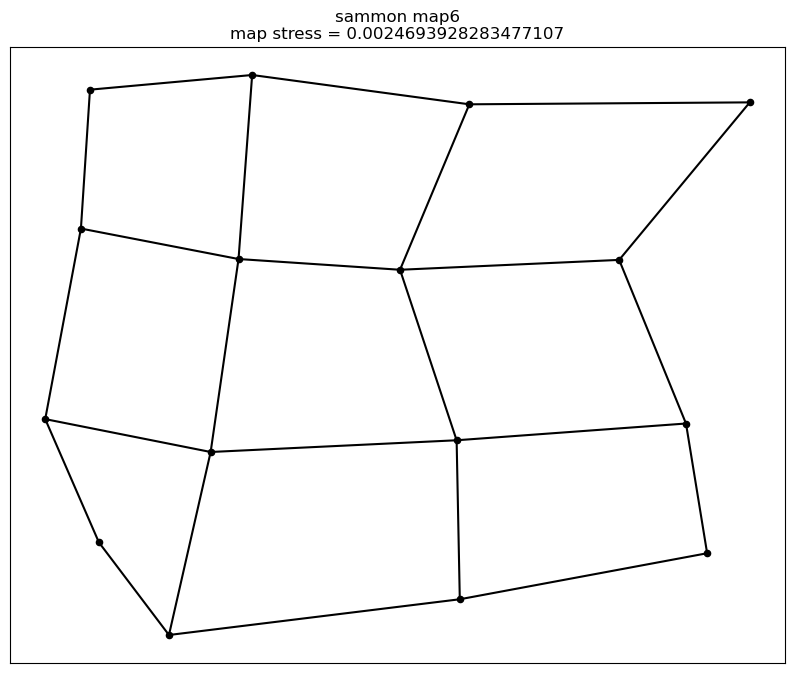

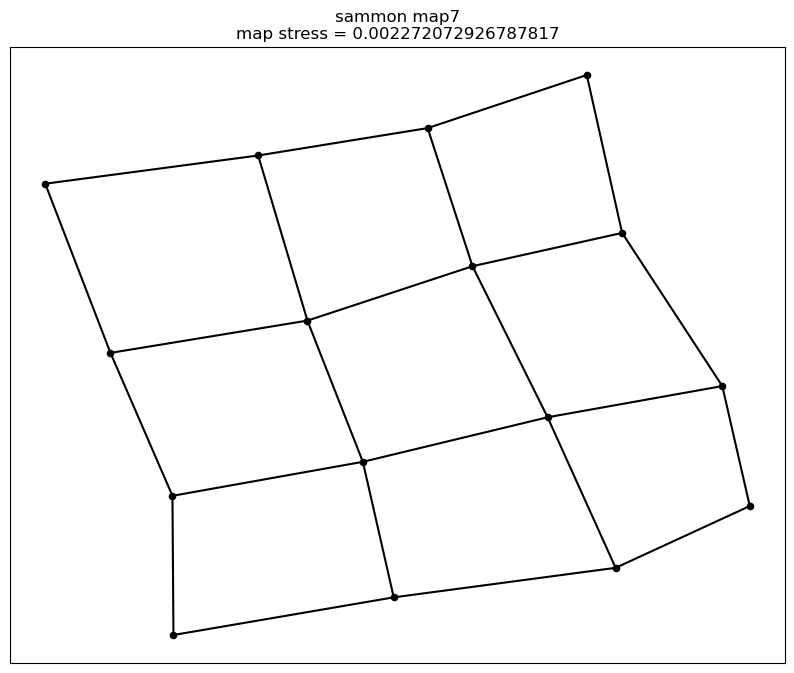

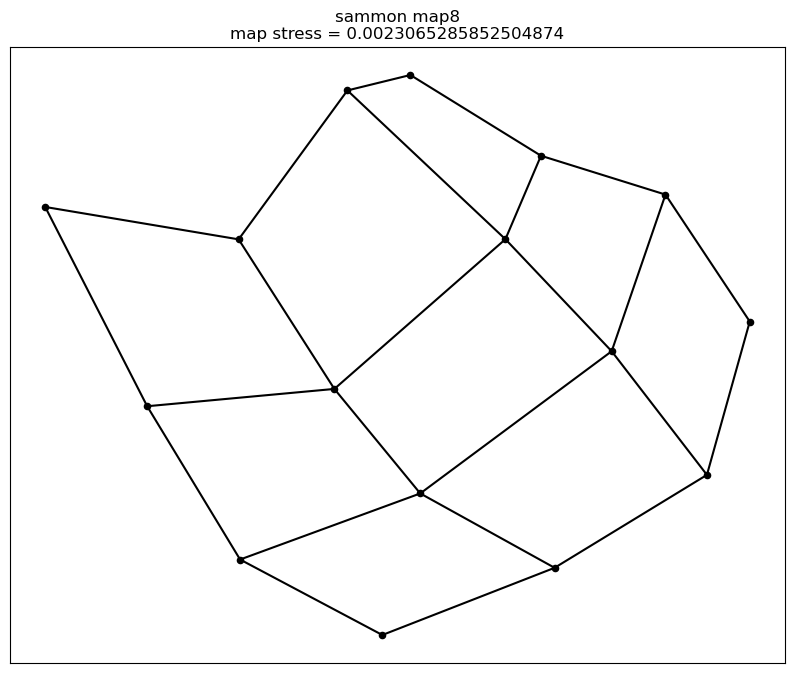

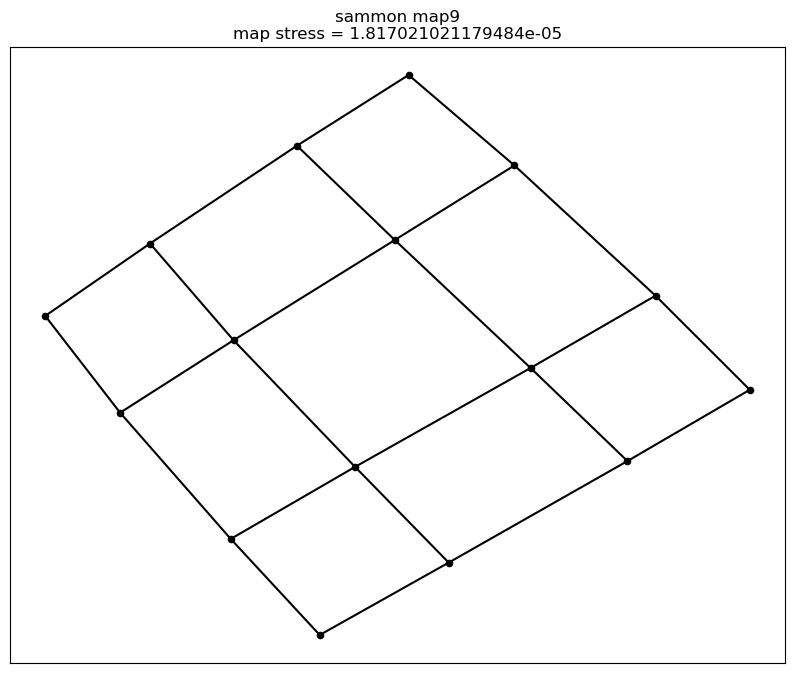

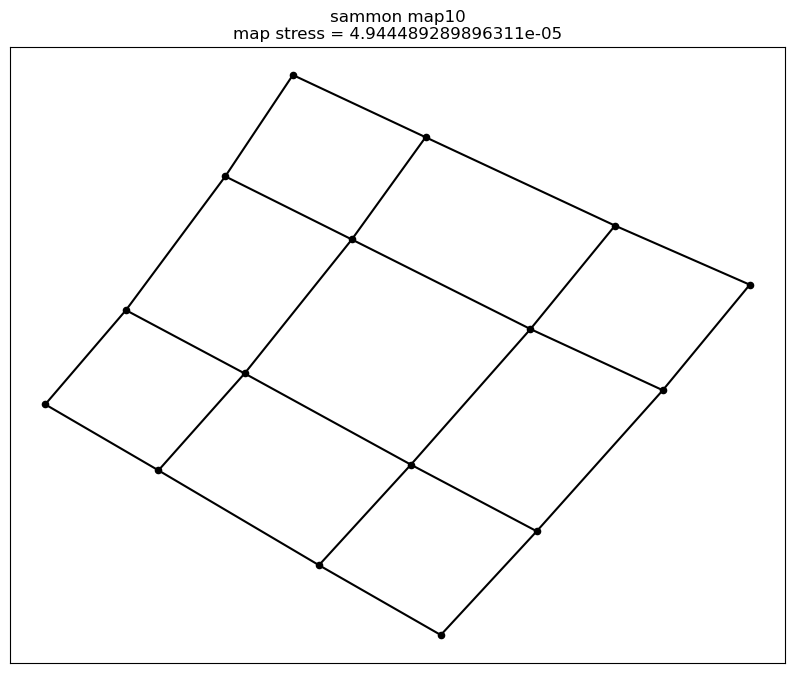

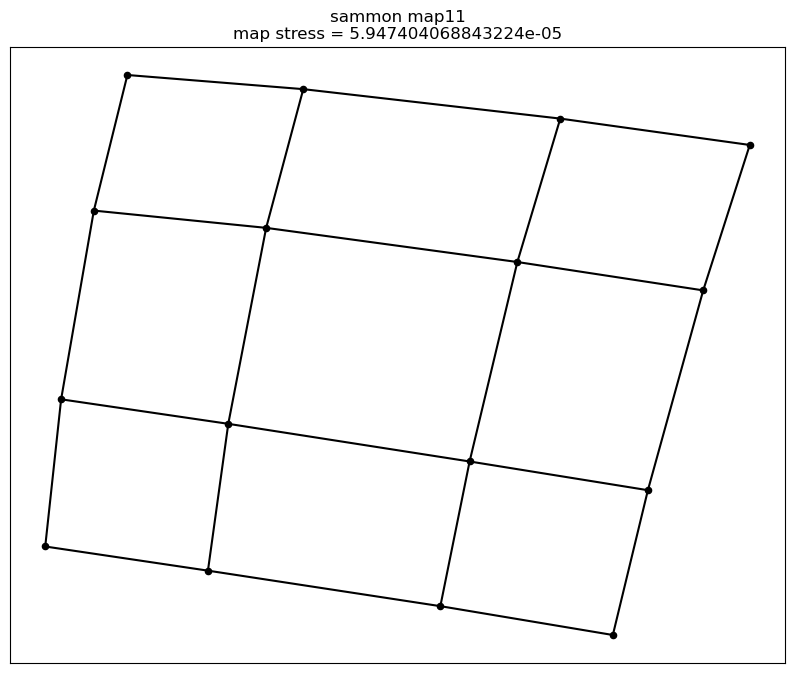

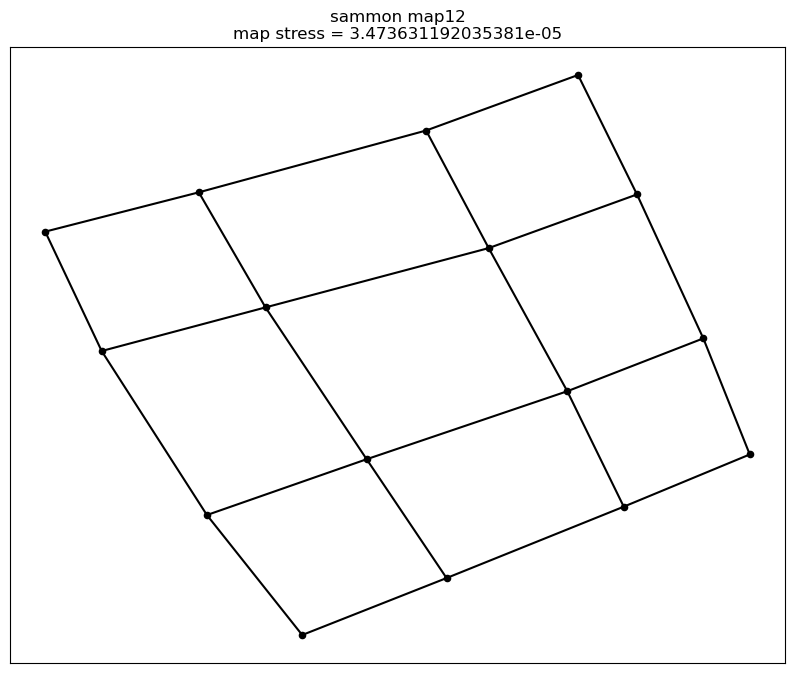

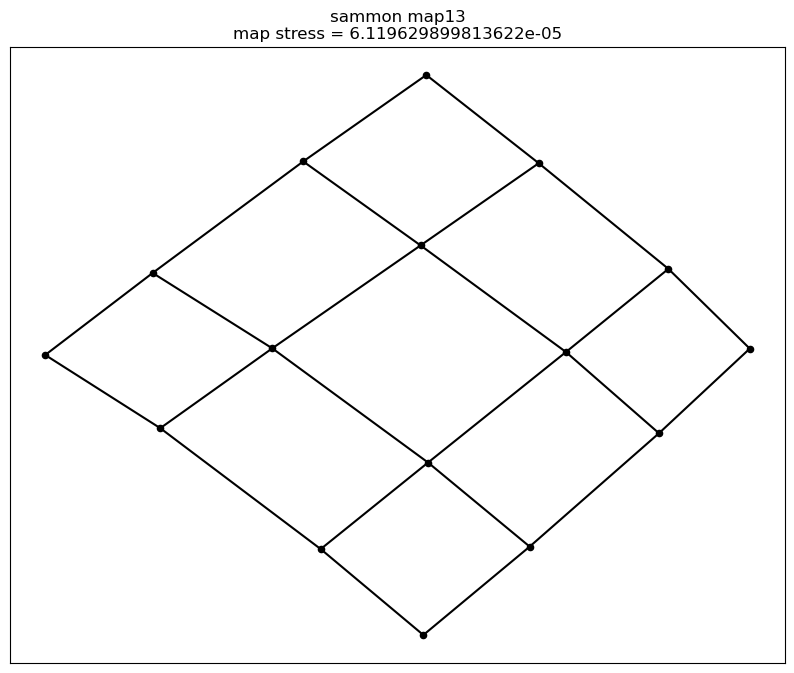

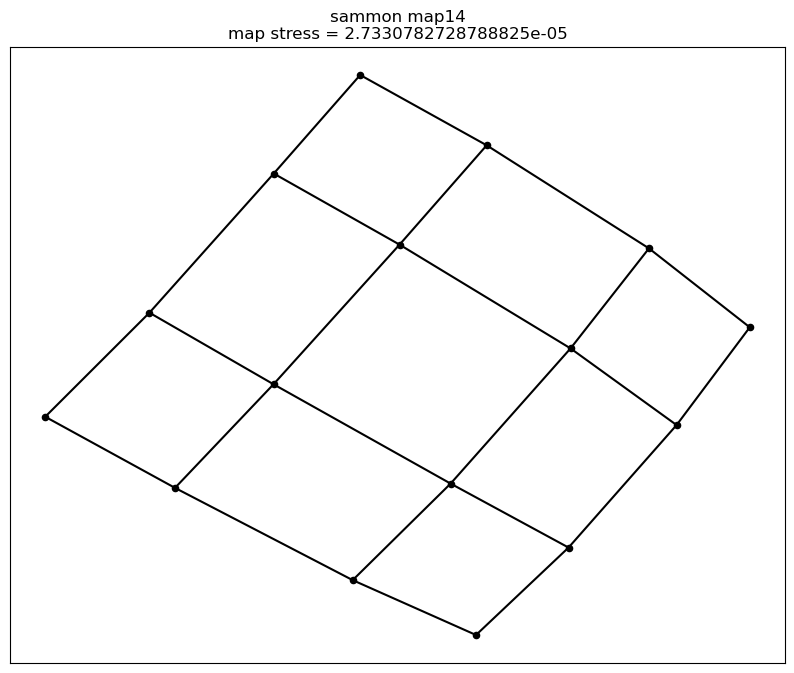

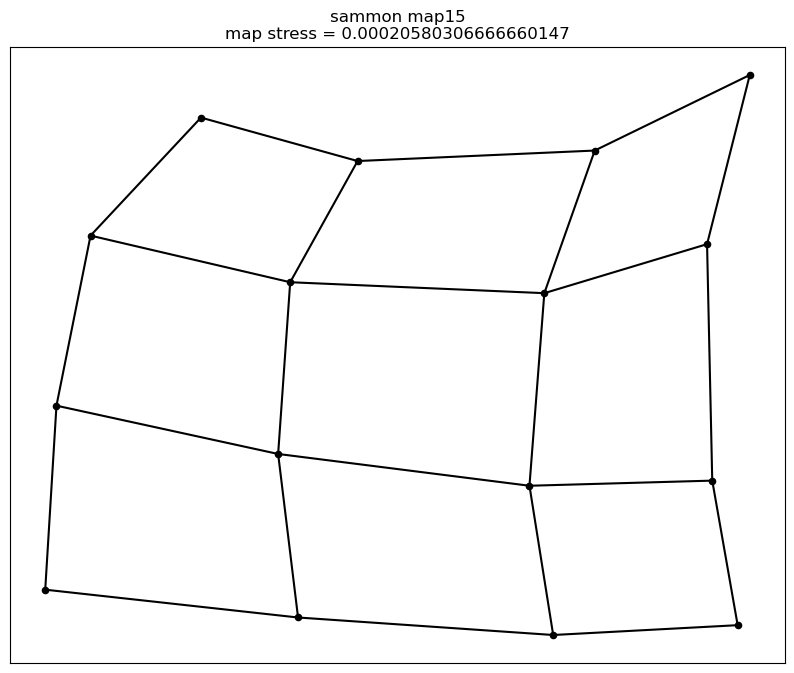

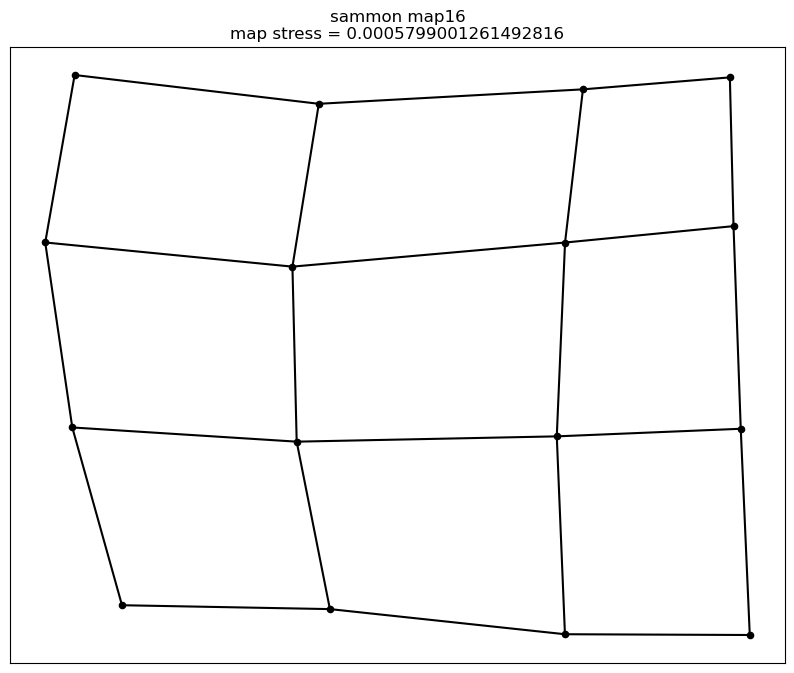

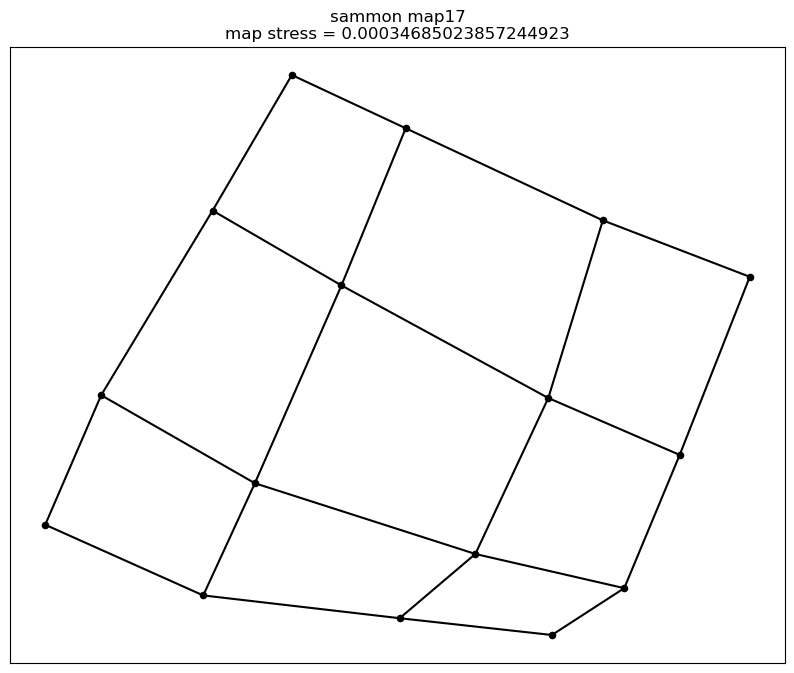

In [ ]:
### For several soms ###

import os

directory = os.fsencode(f"{output_path}/models/")
psl_data = psl_data = normalize_data(ds_regridded['PSL'].compute().values.reshape(num_ensembles*num_times, num_lats*num_lons))

for n in range(18):
    filename = f"{output_path}/models/som{n}.pickle"
    print(filename)


    with open(filename, 'rb') as infile:
        som = pickle.load(infile)

    som_row = n_neurons
    som_col = m_neurons
    input_length = psl_data.shape[1]

    # Calculate sammon coordinates (y) for map and "map stress" (E)
    [y,E] = sammon.sammon(som.get_weights().reshape(som_col*som_row, input_length),2,display=1)

    # Plot Sammon map nodes
    fig = plt.figure(figsize=(10,8))
    plt.scatter(y[:,0], y[:,1], s=20, c='black', marker='o')

    # Add lines between nodes
    tmp = np.reshape(y,(som_col,som_row,2))
    len_x, len_y, len_z = tmp.shape

    # add vertical lines
    for i in range(len_x-1):
        for j in range(len_y):
            plt.plot(tmp[i:i+2,j,0],tmp[i:i+2,j,1],c='black')

    # add horizontal lines
    for i in range(len_x):
        for j in range(len_y-1):
            plt.plot(tmp[i,j:j+2,0],tmp[i,j:j+2,1],c='black')  

    plt.xticks([])
    plt.yticks([])
    plt.title(r"sammon map" f"{n}" "\n" r"map stress = "+str(E), fontsize=12)

    # save figure
    fout = f'{output_path}/sammons/sammon{n}.png'
    plt.savefig(fout, bbox_inches='tight', dpi=200)